In [ ]:
%pip install numpy  # install the libraries into this notebook's Python

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [4]:
%pip install pandas 

  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------- ----------- 7.9/10.9 MB 49.9 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 37.6 MB/s  0:00:00
Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl (12.7 MB)

   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- -------------------------- 1/3 [numpy]
   ------------- --------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 24.8 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ----- ---------------------------------- 1/7 [pillow]
   --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import numpy as np  # NumPy for the maths (compound annual rate)
import pandas as pd  # Pandas to read and organize the data
import matplotlib.pyplot as plt  # Matplotlib to draw the graph

In [23]:
df = pd.read_csv('STATIC_INFLATIONCALC.csv', skiprows=8)  # skip the 8 info lines at the top of the Bank of Canada file

df.columns = ["Date", "CPI"]  # rename the columns to simple names

df["Date"] = pd.to_datetime(df["Date"])  # turn the date text into real dates

df["Change"] = df["CPI"].pct_change(12) * 100  # annual % change = this month vs. same month last year
annual = df.groupby(df["Date"].dt.year)["CPI"].mean().round(1)  # yearly average CPI, which the BoC calculator uses


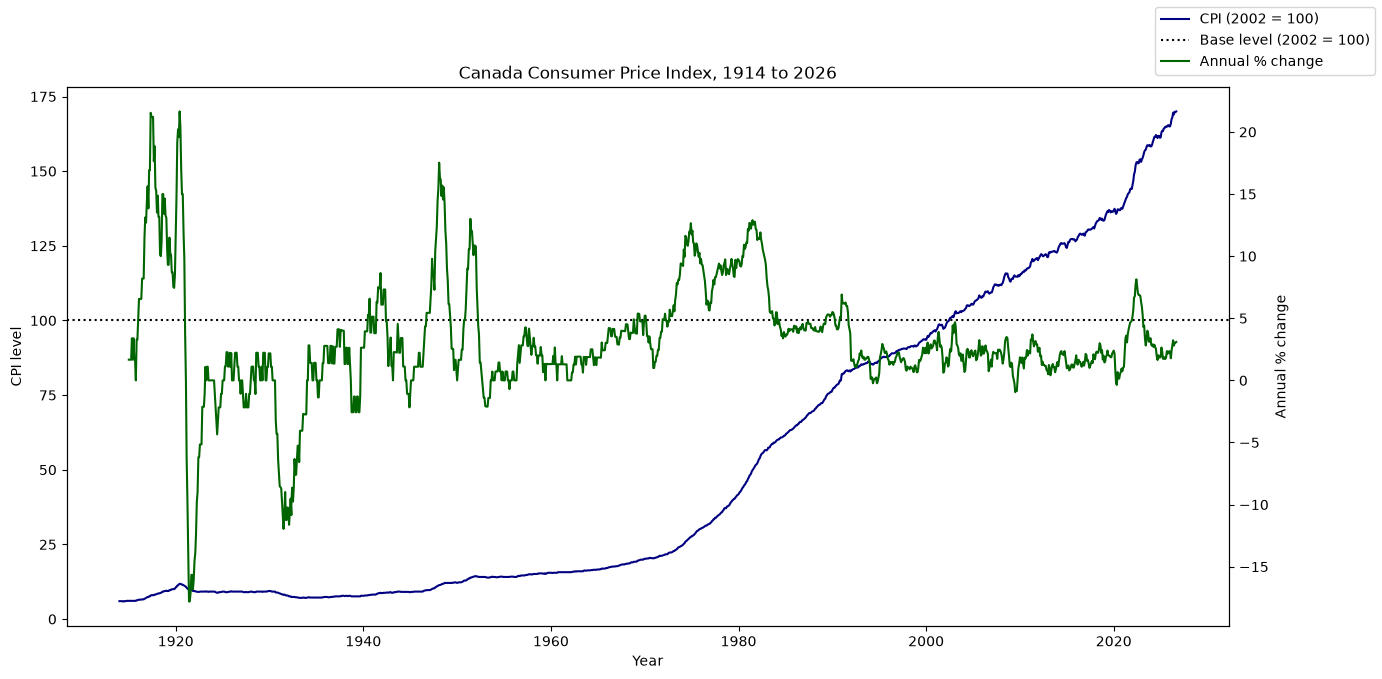

In [24]:
# ---------- 2. Graph ----------
fig, ax1 = plt.subplots(figsize=(15, 7))# create the figure and the left axis

ax1.plot(df["Date"], df["CPI"], color="navy", label="CPI (2002 = 100)")  # CPI line on the left axis
ax1.axhline(100, color="black", linestyle=":", label="Base level (2002 = 100)")  # dotted line through the base level

ax1.set_xlabel("Year")  # x-axis label
ax1.set_ylabel("CPI level")  # left y-axis label
ax2 = ax1.twinx()  # second y-axis on the right side

ax2.plot(df["Date"], df["Change"], color="darkgreen", label="Annual % change")  # % change on the right axis
ax2.set_ylabel("Annual % change")  # right y-axis label
plt.title('Canada Consumer Price Index, 1914 to 2026')  # graph title
fig.legend() # one legend for both axes, below the graph
plt.show() # display the graph



In [28]:
def get_price():  # asks for a price until a valid one is entered
    while True:  # keep asking until the input is valid
        text = input("Price of goods/services: ").replace(",", "").replace("$", "").replace(" ", "")  # allow $, commas and spaces
        try:  # try to turn the text into a number
            price = float(text)  # convert to a number
            if price > 0: return price  # only positive prices are accepted
            print("The price must be greater than 0.")  # message for 0 or negative
        except ValueError:  # text was not a number
            print("Please enter a number, e.g. 100.")  # error message

NEED TO GFINISH

In [29]:
def get_date(label):  # asks for a date until a valid one is entered
    while True:  # keep asking until the input is valid
        text = input(f"{label} (YYYY-MM, from {first:%Y-%m} to {last:%Y-%m}): ").strip()  # read the date as text
        try:  # try to read the year and month
            year, month = text.split("-")  # extract the year and the month from the date
            date = pd.Timestamp(int(year), int(month), 1)  # build a date (fails if the month is not 1-12)
            if first <= date <= last: return date  # date must be inside the data set
            print(f"The date must be between {first:%B %Y} and {last:%B %Y}.")  # out of range message
        except ValueError:  # wrong format or impossible month
            print("Please use the format YYYY-MM, e.g. 2000-01.")  # error message

In [30]:
def month_calculator(price, date1, date2):  # calculator that uses months instead of years
    cpi1 = df.loc[df["Date"] == date1, "CPI"].iloc[0]  # CPI for the first month
    cpi2 = df.loc[df["Date"] == date2, "CPI"].iloc[0]  # CPI for the second month
    months = (date2.year - date1.year) * 12 + (date2.month - date1.month)  # number of months between the dates
    years = months / 12  # convert months to years
    cost2 = price * cpi2 / cpi1  # BoC formula: Cost2 = Cost1 x (CPI2 / CPI1)
    change = (cost2 - price) / price * 100  # BoC formula: percent change
    rate = (np.power(cpi2 / cpi1, 1 / years) - 1) * 100 if years != 0 else 0  # compound average yearly rate
    print(f"\nA basket of goods and services that cost ${price:,.2f} CAD in {date1:%B %Y} would cost ${cost2:,.2f} CAD in {date2:%B %Y}.")  # main result
    print(f"Percent change: {change:.2f}%")  # percent change
    print(f"Number of years: {round(abs(years), 2)}")  # years between the two dates
    print(f"Average annual rate of inflation / decline in the value of money: {rate:.2f}%")  # yearly rate
    print(f"CPI for {date1:%B %Y}: {cpi1:.1f}")  # CPI for the first month
    print(f"CPI for {date2:%B %Y}: {cpi2:.1f}")  # CPI for the second month

# ---------- Run the enhanced calculator ----------
print("Enhanced Inflation Calculator (month and year)")  # heading
month_calculator(get_price(), get_date("First date"), get_date("Second date"))  # ask the user and show the results

Enhanced Inflation Calculator (month and year)
Please enter a number, e.g. 100.
Please enter a number, e.g. 100.
The price must be greater than 0.
The price must be greater than 0.
The price must be greater than 0.
Please use the format YYYY-MM, e.g. 2000-01.

A basket of goods and services that cost $100.00 CAD in February 2000 would cost $100.74 CAD in March 2000.
Percent change: 0.74%
Number of years: 0.08
Average annual rate of inflation / decline in the value of money: 9.30%
CPI for February 2000: 94.1
CPI for March 2000: 94.8
